# 04 · Choosing the decision threshold by cost

The network outputs a fraud probability for each purchase. To act on it, the bank needs a cut-off: purchases scored above the **threshold** are blocked, the rest go through. Until now the threshold was 0.5, an arbitrary choice.

A threshold trades one error for the other. Lowering it blocks more purchases, so fewer frauds get through but more legit customers are bothered. Raising it does the opposite. The right threshold is the one that costs the bank the least, which depends on what each error costs.

The threshold is chosen on the cv set. The test set is still untouched.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))  # make `src` importable from notebooks/

# Reload src/ automatically, so edits to src/ show up without restarting the kernel.
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

# Fixed colors: blue is always "legit", orange is always "fraud".
LEGIT, FRAUD = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=[LEGIT, FRAUD, "#1baf7a", "#eda100"]),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.dpi": 110,
})

In [2]:
from src.data import load_raw, split_by_time
from src.evaluate import FALSE_ALARM_COST, cost_by_threshold, evaluate
from src.features import Preprocessor
from src.train import FINAL_PARAMS, train_neural_net

## Score the cv set with the final network

`FINAL_PARAMS` holds the setup chosen in notebook 03 (fraud weight 10, learning rate 1e-3, early stopping, seed 0), so this is the same network.

In [3]:
split = split_by_time(load_raw())
prep = Preprocessor().fit(split.train)
X_train, y_train = prep.transform(split.train)
X_cv, y_cv = prep.transform(split.cv)

model, history = train_neural_net(X_train, y_train, X_cv, y_cv, **FINAL_PARAMS)
cv_prob = model.predict(X_cv, batch_size=4096, verbose=0).ravel()
cv_amount = split.cv["amt"].to_numpy()
print(f"cv PR-AUC: {evaluate(y_cv, cv_prob)['pr_auc']:.4f}")

cv PR-AUC: 0.8755


## The cost model

- A **missed fraud** costs its purchase amount, because the bank refunds the customer. Letting a \$20 fraud through is much cheaper than letting a \$900 one through.
- A **false alarm** costs a fixed amount: a support call, a blocked card, an annoyed customer. It is set to `FALSE_ALARM_COST` in `src/evaluate.py`. This is an assumption rather than something learned from data, so its effect is checked further down.
- Correct decisions cost nothing.

For reference, without any model every fraud gets through:

In [4]:
no_model_cost = cv_amount[y_cv == 1].sum()
print(f"Cost of approving everything: ${no_model_cost:,.0f}")

Cost of approving everything: $1,220,266


## Cost at every threshold

In [5]:
costs = cost_by_threshold(y_cv, cv_prob, cv_amount, false_alarm_cost=FALSE_ALARM_COST)
best_threshold = costs["total_cost"].idxmin()
print(f"False alarm cost: ${FALSE_ALARM_COST} | cheapest threshold: {best_threshold}")

False alarm cost: $10 | cheapest threshold: 0.23


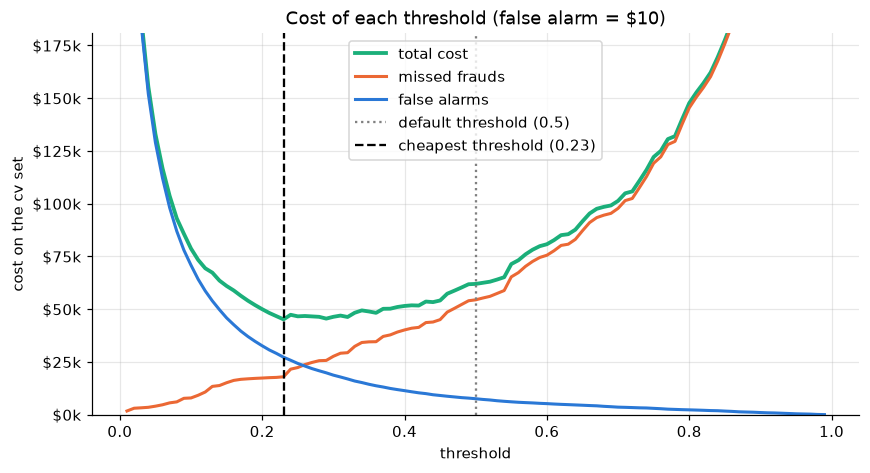

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(costs.index, costs["total_cost"], lw=2.5, color="#1baf7a", label="total cost")
ax.plot(costs.index, costs["missed_fraud_cost"], lw=2, color=FRAUD, label="missed frauds")
ax.plot(costs.index, costs["false_alarm_cost"], lw=2, color=LEGIT, label="false alarms")
ax.axvline(0.5, ls=":", c="gray", label="default threshold (0.5)")
ax.axvline(best_threshold, ls="--", c="black", label=f"cheapest threshold ({best_threshold})")
# The curve explodes near 0, where almost everything is flagged; zoom in on the useful range.
ax.set_ylim(0, 4 * costs["total_cost"].min())
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v / 1000:.0f}k"))
ax.set_xlabel("threshold")
ax.set_ylabel("cost on the cv set")
ax.set_title(f"Cost of each threshold (false alarm = ${FALSE_ALARM_COST})")
ax.legend()
fig.savefig(FIGURES / "threshold_cost.png", bbox_inches="tight")

Each error type pulls in its own direction. Missed-fraud cost grows with the threshold, because more frauds slip under it; false-alarm cost falls, because fewer purchases are flagged. The total is lowest where the two balance, and the bottom of the curve is fairly flat, so thresholds close to the best one cost almost the same.

## Default threshold vs cost-based threshold

In [7]:
def summary(threshold):
    row = costs.loc[threshold]
    metrics = evaluate(y_cv, cv_prob, threshold=threshold)
    return {
        "missed frauds": int(row["missed_frauds"]),
        "missed fraud amount": round(row["missed_fraud_cost"]),
        "false alarms": int(row["false_alarms"]),
        "total cost": round(row["total_cost"]),
        "precision": round(metrics["precision"], 3),
        "recall": round(metrics["recall"], 3),
    }

comparison = pd.DataFrame({"threshold 0.5": summary(0.5), f"threshold {best_threshold}": summary(best_threshold)})
comparison

,threshold 0.5,threshold 0.23
missed frauds,363.000,204.000
missed fraud amount,54419.000,17942.000
false alarms,754.000,2722.000
total cost,61959.000,45162.000
precision,0.718,0.433
recall,0.841,0.911


In [8]:
saving = 1 - costs.loc[best_threshold, "total_cost"] / costs.loc[0.5, "total_cost"]
print(f"Cost reduction vs the 0.5 threshold: {100 * saving:.0f}%")
print(f"Cost reduction vs no model: {100 * (1 - costs.loc[best_threshold, 'total_cost'] / no_model_cost):.1f}%")

Cost reduction vs the 0.5 threshold: 27%
Cost reduction vs no model: 96.3%


## How much does the assumed false alarm cost matter?

The false alarm cost is a guess. Repeating the search for other values shows how sensitive the decision is to it:

In [9]:
sensitivity = {}
for fa_cost in [2, 5, 10, 25, 50]:
    c = cost_by_threshold(y_cv, cv_prob, cv_amount, false_alarm_cost=fa_cost)
    t = c["total_cost"].idxmin()
    sensitivity[f"${fa_cost}"] = {
        "cheapest threshold": t,
        "missed frauds": int(c.loc[t, "missed_frauds"]),
        "false alarms": int(c.loc[t, "false_alarms"]),
        "total cost": round(c.loc[t, "total_cost"]),
    }
pd.DataFrame(sensitivity).T.rename_axis("false alarm cost")

,cheapest threshold,missed frauds,false alarms,total cost
false alarm cost,,,,
$2,0.11,106.0,6418.0,22013.0
$5,0.23,204.0,2722.0,31552.0
$10,0.23,204.0,2722.0,45162.0
$25,0.42,324.0,1034.0,67214.0
$50,0.53,379.0,659.0,90381.0


## Conclusions

- With a false alarm priced at \$10, the cheapest threshold is **0.23**. It cuts the cost on cv from \$61,959 at the default 0.5 to \$45,162 (27% less), and the model as a whole avoids 96% of the \$1.22 million that frauds would cost with no model at all.
- The lower threshold accepts more false alarms (2,722 instead of 754) to catch more frauds (recall rises from 84% to 91%). The trade pays off: the amount lost to missed frauds falls from \$54,419 to \$17,942.
- Precision drops to 43%, so fewer than half of the flagged purchases are fraud. That is only acceptable because a false alarm is assumed to be cheap. In practice, this is where a softer action, such as asking the customer to confirm the purchase in the app, fits better than blocking the card.
- The decision depends on the assumed false alarm cost. Between \$5 and \$10 the threshold stays at 0.23, but at \$50 it moves to 0.53. This number has to come from the business, not from the model.
- The threshold was chosen on the same cv set used to tune the network, so these savings are slightly optimistic. The test set will give the honest figure.